In [148]:
from pathlib import Path

DATA_PATH = Path("nigeria_food_prices_practice.csv")
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["price_ngn"] = pd.to_numeric(df["price_ngn"], errors="coerce")
df["markets_surveyed"] = pd.to_numeric(df["markets_surveyed"], errors="coerce")
df = df.dropna(subset=["date", "price_ngn"]).copy()
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()

print(f"Rows: {len(df):,} | States: {df['state'].nunique()} | Items: {df['item'].nunique()}")
print(f"Date range: {df['date'].min():%Y-%m} to {df['date'].max():%Y-%m}")
display(df.head())
display(df.isna().sum().rename("missing values").to_frame())

Rows: 922 | States: 17 | Items: 6
Date range: 2023-01 to 2025-12


,date,state,item,price_ngn,markets_surveyed,month
0,2025-11-01,Anambra,Beans (1kg),2708.40,31.0,2025-11-01
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0,2023-06-01
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0,2024-06-01
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0,2025-07-01
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN,2023-09-01


,missing values
date,0
state,0
item,0
price_ngn,0
markets_surveyed,25
month,0


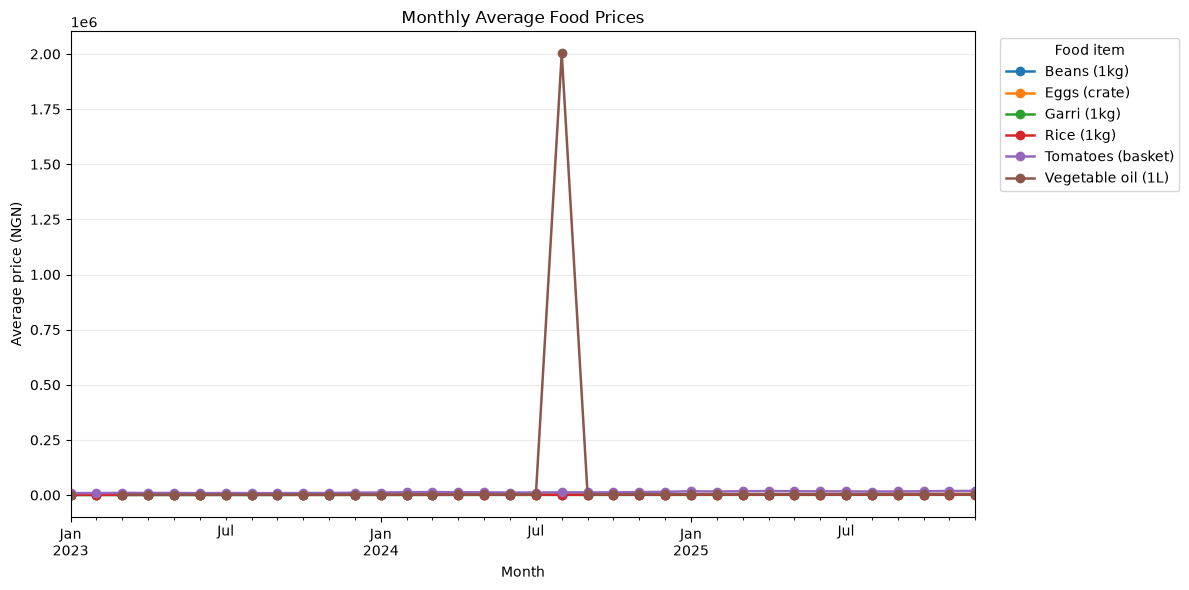

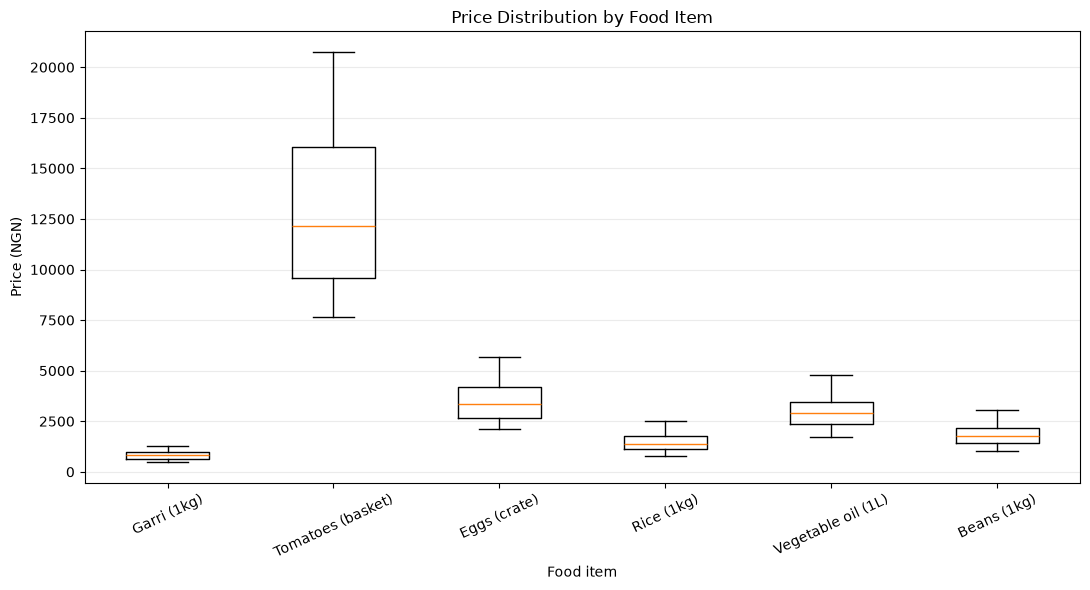

In [149]:
# Average price trend by food item
monthly_prices = df.groupby(["month", "item"])["price_ngn"].mean().unstack()
ax = monthly_prices.plot(figsize=(12, 6), marker="o", linewidth=1.8)
ax.set(title="Monthly Average Food Prices", xlabel="Month", ylabel="Average price (NGN)")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Food item", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Price distributions for the six most frequently recorded items
top_items = df["item"].value_counts().head(6).index.tolist()
price_groups = [df.loc[df["item"] == item, "price_ngn"].dropna() for item in top_items]
fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(price_groups, tick_labels=top_items, showfliers=False)
ax.set(title="Price Distribution by Food Item", xlabel="Food item", ylabel="Price (NGN)")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

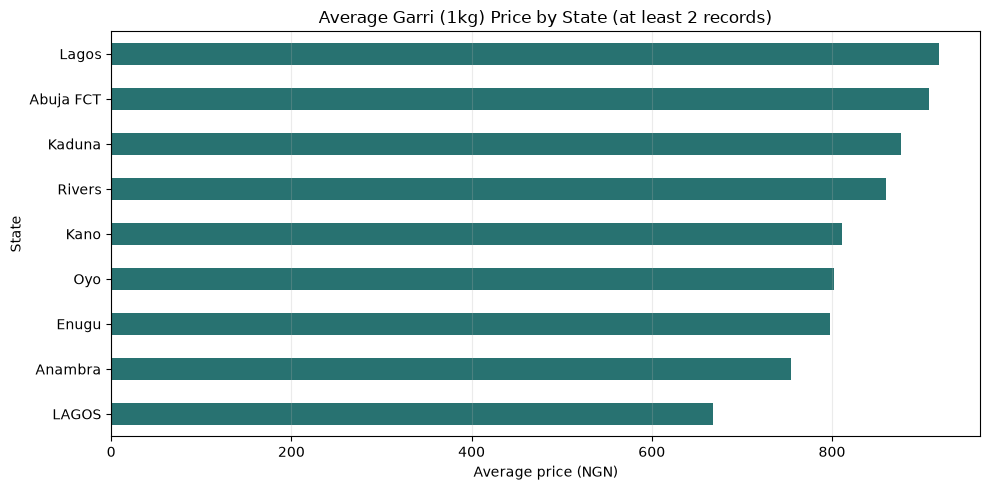

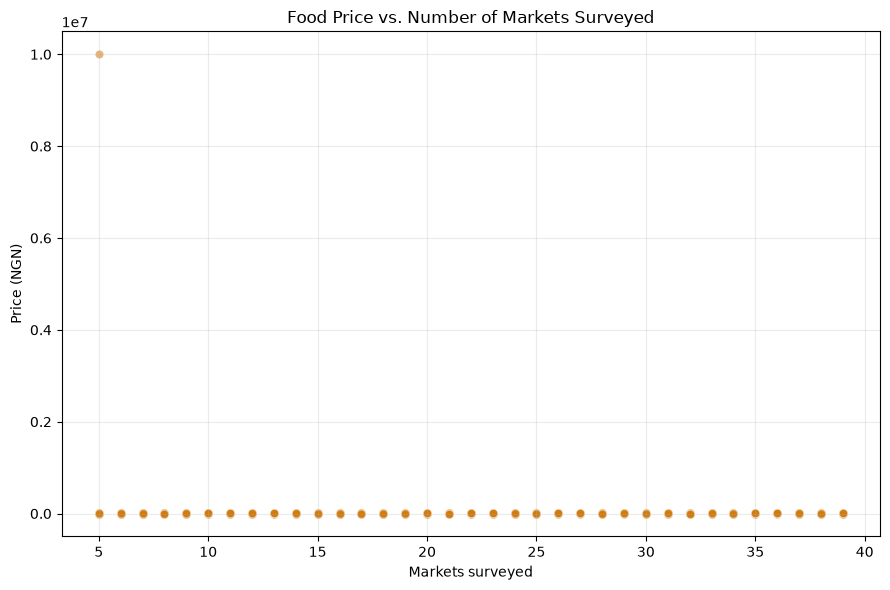

Most recorded item: Garri (1kg)
Price / markets surveyed correlation: -0.06


In [150]:
# State comparison for the most frequently recorded food item
most_recorded_item = df["item"].value_counts().idxmax()
state_prices = (
    df.loc[df["item"] == most_recorded_item]
    .groupby("state")["price_ngn"]
    .agg(["mean", "count"])
    .query("count >= 2")
    .sort_values("mean")
)
fig, ax = plt.subplots(figsize=(10, max(5, len(state_prices) * 0.28)))
state_prices["mean"].plot(kind="barh", ax=ax, color="#287271")
ax.set(title=f"Average {most_recorded_item} Price by State (at least 2 records)", xlabel="Average price (NGN)", ylabel="State")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# Price versus survey coverage; each point is one state-item observation
survey_data = df.dropna(subset=["markets_surveyed"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(survey_data["markets_surveyed"], survey_data["price_ngn"], alpha=0.55, color="#d17b0f", edgecolors="white", linewidths=0.4)
ax.set(title="Food Price vs. Number of Markets Surveyed", xlabel="Markets surveyed", ylabel="Price (NGN)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Most recorded item: {most_recorded_item}")
print(f"Price / markets surveyed correlation: {survey_data['price_ngn'].corr(survey_data['markets_surveyed']):.2f}")

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [152]:
df=pd.read_csv(r"C:\Users\Aminu Ibrahim\Desktop\EDA Project\nigeria_food_prices_practice.csv")
df

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.4,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [153]:
df.head(10)

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.4,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [154]:
df.isnull().count()

date                975
state               975
item                975
price_ngn           975
markets_surveyed    975
dtype: int64

In [155]:
df.notna().sum()

date                975
state               975
item                975
price_ngn           933
markets_surveyed    949
dtype: int64

In [156]:
df.isna().sum()

date                 0
state                0
item                 0
price_ngn           42
markets_surveyed    26
dtype: int64

In [157]:
df['price_ngn'].dtypes

<StringDtype(storage='python', na_value=nan)>

In [158]:
"1000" < "711"

True

In [159]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 975 entries, 0 to 974
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              975 non-null    str    
 1   state             975 non-null    str    
 2   item              975 non-null    str    
 3   price_ngn         933 non-null    str    
 4   markets_surveyed  949 non-null    float64
dtypes: float64(1), str(4)
memory usage: 38.2 KB


In [160]:
df.describe(include='all')

,date,state,item,price_ngn,markets_surveyed
count,975,975,975,933,949.000000
unique,36,17,6,919,NaN
top,2023-10-01,Anambra,Garri (1kg),1294.72,NaN
freq,34,129,175,3,NaN
mean,NaN,NaN,NaN,NaN,22.100105
std,NaN,NaN,NaN,NaN,10.055935
min,NaN,NaN,NaN,NaN,5.000000
25%,NaN,NaN,NaN,NaN,13.000000
50%,NaN,NaN,NaN,NaN,22.000000
75%,NaN,NaN,NaN,NaN,31.000000


In [161]:
df.isna()

,date,state,item,price_ngn,markets_surveyed
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


In [162]:
df['state'].unique()

<StringArray>
[  'Anambra',      'Kano',       'Oyo',     'Enugu', 'Abuja FCT',    'Kaduna',
     'Lagos',    'Rivers',     'LAGOS',     'enugu',       'oyo',    'kaduna',
      'kano', 'abuja fct',     'lagos',   'anambra',    'rivers']
Length: 17, dtype: str

In [163]:
df.shape

(975, 5)

In [164]:
df['price_ngn'].max()

'₦700'

In [165]:
df_clean= df.drop_duplicates()
df_clean

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.4,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [166]:
df_clean.shape

(960, 5)

In [167]:
df_clean.duplicated().sum()

np.int64(0)

In [168]:
df_clean.head(10)

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.4,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [169]:
bad = df_clean[df_clean["price_ngn"].str.contains(r"[^0-9.]", na=False)]
bad.shape
bad

,date,state,item,price_ngn,markets_surveyed
280,2025-12-01,Abuja FCT,Tomatoes (basket),"₦22,549",11.0
389,2024-01-01,Kano,Garri (1kg),₦700,20.0
449,2025-02-01,Anambra,Tomatoes (basket),"₦15,581",NaN
476,2025-08-01,Kano,Beans (1kg),"₦2,435",35.0
668,2023-12-01,Kaduna,Beans (1kg),"₦1,311",21.0
688,2023-10-01,Oyo,Beans (1kg),"₦1,416",14.0
721,2025-10-01,LAGOS,Rice (1kg),"₦1,872",9.0
766,2023-02-01,Enugu,Vegetable oil (1L),"₦1,862",5.0
850,2023-03-01,Kano,Garri (1kg),₦520,9.0
853,2024-05-01,Lagos,Tomatoes (basket),"₦14,089",12.0


In [170]:
df_clean=df['price_ngn'].str.replace('₦','').str.replace(',', '')
df_clean

0        2708.4
1       8871.24
2        711.89
3       3734.86
4       2428.03
5       4623.09
6       1268.79
7       4263.18
8      19609.06
9       1038.35
10      2638.54
11      1582.16
12      2162.41
13       669.26
14      1857.29
15       1695.3
16      2992.91
17      2069.98
18      2104.09
19      2093.17
20      1070.62
21      1239.35
22      2157.15
23       843.72
24     11218.76
25      1110.32
26      1065.64
27      2057.13
28       2192.0
29      1114.76
30      2346.44
31      3388.05
32     15365.75
33       859.07
34      1429.02
35      3237.09
36       755.63
37      2717.36
38      5465.25
39       510.05
40      9151.77
41      3269.09
42     12115.82
43      3312.43
44      2522.27
45      4406.42
46      2321.23
47      1952.18
48      1195.86
49      1703.24
50      3291.97
51       489.95
52      1418.17
53      1262.99
54      2385.88
55      9505.74
56      2791.27
57     12286.48
58      1429.05
59       1410.2
60      1083.51
61       818.84
62      

In [171]:
pd.Series.str.replace

<function pandas.core.strings.accessor.StringMethods.replace(self, pat: 'str | re.Pattern | dict', repl: 'str | Callable | None' = None, n: 'int' = -1, case: 'bool | None' = None, flags: 'int' = 0, regex: 'bool' = False)>

In [172]:
df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean.shape

(960, 5)

In [173]:
df_clean.dtypes

date                    str
state                   str
item                    str
price_ngn               str
markets_surveyed    float64
dtype: object

In [174]:
df_clean['price_ngn'] = df_clean['price_ngn'].str.replace('₦', '').str.replace(',', '')

In [175]:
df_clean['price_ngn'].str.contains('₦', na=False).sum()

np.int64(0)

In [176]:
df_clean['price_ngn']= pd.to_numeric(df_clean['price_ngn'])

In [177]:
df_clean.dtypes

date                    str
state                   str
item                    str
price_ngn           float64
markets_surveyed    float64
dtype: object

In [178]:
df_clean['price_ngn'].dtype

dtype('float64')

In [179]:
df_clean['date']= pd.to_datetime(df_clean['date'])

In [180]:
df_clean['date'].dtypes

dtype('<M8[us]')

In [181]:
df_clean['date'].dt.year.unique()

array([2025, 2023, 2024], dtype=int32)

In [182]:
df_clean['date'].min() and df_clean['date'].max()

Timestamp('2025-12-01 00:00:00')

In [183]:
df_clean['date'].nunique()

36

In [184]:
df_clean['price_ngn'].isna().sum()

np.int64(40)

In [185]:
df_clean['price_ngn'].min()

np.float64(471.23)

In [186]:
df_clean['price_ngn'].max()

np.float64(9999999.0)

In [187]:
df_clean.head(10).max()

date                2025-11-01 00:00:00
state                               Oyo
item                 Vegetable oil (1L)
price_ngn                      19609.06
markets_surveyed                   37.0
dtype: object

In [188]:
df_clean['date'].dt.month

0      11
1       6
2       6
3       7
4       9
5       1
6      10
7      10
8       1
9       6
10      5
11     11
12      8
13     12
14      4
15     12
16      4
17     10
18      3
19      6
20      4
21      7
22      7
23      5
24      1
25     11
26      4
27     12
28      5
29      1
30      8
31      1
32      8
33     11
34      8
35      1
36      9
37      9
38     12
39      3
40      9
41      6
42      7
43      6
44      1
45      8
46      2
47      3
48      8
49      1
50     11
51      1
52     11
53      5
54      1
55      2
56     11
57      9
58      9
59     10
60     10
61      4
62     10
63     12
64      7
65     12
66      7
67      3
68      8
69      9
70     12
71      6
72      6
73      2
74      8
75      9
76      3
77      3
78      6
79     10
80      4
81     12
82      4
83      9
84      8
85      7
86     11
87      9
88      9
89     12
90      8
91      7
92      1
93      9
94      1
95      7
96      7
97      7
98      2
99      8


In [189]:
df_clean.sort_values(by='price_ngn', ascending=False)

,date,state,item,price_ngn,markets_surveyed
433,2024-08-01,Abuja FCT,Vegetable oil (1L),9999999.00,5.0
279,2025-12-01,Abuja FCT,Tomatoes (basket),22549.00,11.0
867,2025-12-01,Lagos,Tomatoes (basket),20759.11,38.0
440,2025-11-01,Lagos,Tomatoes (basket),20496.00,13.0
77,2025-03-01,Abuja FCT,Tomatoes (basket),20180.09,19.0
162,2025-04-01,Abuja FCT,Tomatoes (basket),20034.77,11.0
559,2025-06-01,Lagos,Tomatoes (basket),19652.59,26.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
379,2025-11-01,Oyo,Tomatoes (basket),19025.49,37.0
400,2025-04-01,Kaduna,Tomatoes (basket),18845.83,37.0


In [190]:
df_clean.tail(10)

,date,state,item,price_ngn,markets_surveyed
950,2023-10-01,Anambra,Beans (1kg),1384.55,30.0
951,2024-02-01,Oyo,Eggs (crate),2774.76,26.0
952,2023-03-01,LAGOS,Tomatoes (basket),8813.53,13.0
953,2024-06-01,Abuja FCT,Beans (1kg),1820.35,22.0
954,2023-12-01,Oyo,Beans (1kg),1446.29,39.0
955,2024-09-01,Kano,Garri (1kg),824.78,19.0
956,2024-11-01,Kano,Rice (1kg),1505.74,11.0
957,2024-07-01,Abuja FCT,Vegetable oil (1L),3186.72,33.0
958,2024-08-01,Anambra,Beans (1kg),1696.93,39.0
959,2023-07-01,Rivers,Garri (1kg),619.78,30.0


In [191]:
df_clean['state'] = df_clean['state'].str.capitalize()
df_clean

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.40,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja fct,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja fct,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja fct,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [192]:
df_clean['state'].value_counts()

state
Lagos        139
Anambra      127
Abuja fct    123
Kano         117
Enugu        117
Kaduna       116
Rivers       115
Oyo          106
Name: count, dtype: int64

In [193]:
df_clean.duplicated().sum()

np.int64(0)

In [194]:
df_clean.shape

(960, 5)

In [195]:
df_clean['price_ngn'].min()

np.float64(471.23)

In [196]:
df_clean['price_ngn'].max()

np.float64(9999999.0)

In [197]:
df_clean['price_ngn'].dtype

dtype('float64')

In [198]:
df_clean['price_ngn'].median()

np.float64(2248.295)

In [199]:
df_clean.columns

Index(['date', 'state', 'item', 'price_ngn', 'markets_surveyed'], dtype='str')

In [200]:
df_clean.groupby(by='item')['price_ngn'].max()

item
Beans (1kg)              3070.50
Eggs (crate)             5674.19
Garri (1kg)              1276.85
Rice (1kg)               2524.01
Tomatoes (basket)       22549.00
Vegetable oil (1L)    9999999.00
Name: price_ngn, dtype: float64

In [201]:
df_clean.idxmax()

date                 38
state                25
item                  3
price_ngn           433
markets_surveyed     32
dtype: int64

In [202]:
df_clean.loc[433]

date                2024-08-01 00:00:00
state                         Abuja fct
item                 Vegetable oil (1L)
price_ngn                     9999999.0
markets_surveyed                    5.0
Name: 433, dtype: object

In [203]:
df_clean.loc[433].replace(9999999.0, 'NaN')

date                2024-08-01 00:00:00
state                         Abuja fct
item                 Vegetable oil (1L)
price_ngn                           NaN
markets_surveyed                    5.0
Name: 433, dtype: object

In [204]:
df_clean.loc[433]

date                2024-08-01 00:00:00
state                         Abuja fct
item                 Vegetable oil (1L)
price_ngn                     9999999.0
markets_surveyed                    5.0
Name: 433, dtype: object

In [205]:
df_clean['price_ngn'].max()

np.float64(9999999.0)

In [206]:
df_clean.loc[433, 'price_ngn'] = np.nan

In [207]:
df_clean.loc[433]

date                2024-08-01 00:00:00
state                         Abuja fct
item                 Vegetable oil (1L)
price_ngn                           NaN
markets_surveyed                    5.0
Name: 433, dtype: object

In [208]:
df_clean.groupby(by='item')['price_ngn'].median()

item
Beans (1kg)            1781.980
Eggs (crate)           3342.470
Garri (1kg)             805.080
Rice (1kg)             1406.485
Tomatoes (basket)     12358.400
Vegetable oil (1L)     2911.470
Name: price_ngn, dtype: float64

In [209]:
df_clean.isna()

,date,state,item,price_ngn,markets_surveyed
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


In [210]:
df_clean['price_ngn'] = df_clean['price_ngn'].fillna(df_clean.groupby(by='item')['price_ngn'].transform('median'))
df_clean

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.400,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.240,25.0
2,2024-06-01,Oyo,Garri (1kg),711.890,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.860,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.030,NaN
5,2025-01-01,Abuja fct,Eggs (crate),4623.090,5.0
6,2023-10-01,Abuja fct,Beans (1kg),1268.790,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.180,34.0
8,2025-01-01,Abuja fct,Tomatoes (basket),19609.060,17.0
9,2023-06-01,Kano,Rice (1kg),1038.350,32.0


In [211]:
df_clean.isna().sum()

date                 0
state                0
item                 0
price_ngn            0
markets_surveyed    25
dtype: int64

In [212]:
df_clean.loc[433]

date                2024-08-01 00:00:00
state                         Abuja fct
item                 Vegetable oil (1L)
price_ngn                       2911.47
markets_surveyed                    5.0
Name: 433, dtype: object

In [213]:
df_clean['price_ngn'] = df_clean['price_ngn'].fillna(
    df_clean.groupby(by='item')['price_ngn'].transform('median')
)
df_clean

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.400,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.240,25.0
2,2024-06-01,Oyo,Garri (1kg),711.890,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.860,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.030,NaN
5,2025-01-01,Abuja fct,Eggs (crate),4623.090,5.0
6,2023-10-01,Abuja fct,Beans (1kg),1268.790,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.180,34.0
8,2025-01-01,Abuja fct,Tomatoes (basket),19609.060,17.0
9,2023-06-01,Kano,Rice (1kg),1038.350,32.0


In [214]:
df_clean['markets_surveyed'].median()

np.float64(22.0)

In [215]:
df_clean['markets_surveyed'] = df_clean['markets_surveyed'].fillna(
    df_clean['markets_surveyed'].median())

In [216]:
df_clean['markets_surveyed'].isna().sum()

np.int64(0)

In [217]:
df_clean['markets_surveyed'] = df_clean['markets_surveyed'].fillna(
    df_clean['markets_surveyed'].median())

In [218]:
df_clean.duplicated().sum()
df_clean['price_ngn'].max()

np.float64(22549.0)

In [219]:
df_clean['state']= df_clean['state'].str.replace('Abuja fct', 'Abuja FCT')

In [220]:
df_clean['state']

0        Anambra
1           Kano
2            Oyo
3          Enugu
4        Anambra
5      Abuja FCT
6      Abuja FCT
7         Kaduna
8      Abuja FCT
9           Kano
10        Kaduna
11         Enugu
12         Enugu
13          Kano
14         Enugu
15     Abuja FCT
16        Kaduna
17           Oyo
18        Kaduna
19         Lagos
20     Abuja FCT
21         Lagos
22           Oyo
23         Lagos
24       Anambra
25        Rivers
26           Oyo
27        Kaduna
28       Anambra
29        Kaduna
30        Rivers
31       Anambra
32        Rivers
33           Oyo
34       Anambra
35          Kano
36        Kaduna
37          Kano
38       Anambra
39           Oyo
40         Lagos
41          Kano
42           Oyo
43        Kaduna
44          Kano
45        Rivers
46         Lagos
47         Lagos
48          Kano
49           Oyo
50           Oyo
51         Enugu
52       Anambra
53         Enugu
54       Anambra
55           Oyo
56        Kaduna
57         Lagos
58          Ka

In [221]:
df_clean.dtypes

date                datetime64[us]
state                          str
item                           str
price_ngn                  float64
markets_surveyed           float64
dtype: object

In [222]:
df_clean['date'].dtypes

dtype('<M8[us]')

In [223]:
df_clean.to_csv('nigeria_food_prices_clean.csv')
df_clean.shape

(960, 5)

In [224]:
df_check=pd.set_option("display.max_rows", None)
df_check

In [225]:
df_clean['price_ngn'].max()

np.float64(22549.0)

In [226]:
df_check=pd.read_csv('nigeria_food_prices_clean.csv')
df

,date,state,item,price_ngn,markets_surveyed
0,2025-11-01,Anambra,Beans (1kg),2708.4,31.0
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,NaN
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0


In [227]:
df_clean['year']= df_clean['date'].dt.year

In [228]:
df_clean.head(10)

,date,state,item,price_ngn,markets_surveyed,year
0,2025-11-01,Anambra,Beans (1kg),2708.40,31.0,2025
1,2023-06-01,Kano,Tomatoes (basket),8871.24,25.0,2023
2,2024-06-01,Oyo,Garri (1kg),711.89,14.0,2024
3,2025-07-01,Enugu,Vegetable oil (1L),3734.86,37.0,2025
4,2023-09-01,Anambra,Vegetable oil (1L),2428.03,22.0,2023
5,2025-01-01,Abuja FCT,Eggs (crate),4623.09,5.0,2025
6,2023-10-01,Abuja FCT,Beans (1kg),1268.79,23.0,2023
7,2025-10-01,Kaduna,Vegetable oil (1L),4263.18,34.0,2025
8,2025-01-01,Abuja FCT,Tomatoes (basket),19609.06,17.0,2025
9,2023-06-01,Kano,Rice (1kg),1038.35,32.0,2023


In [229]:
df_clean['year'].unique()

array([2025, 2023, 2024], dtype=int32)

In [230]:
item_price_per_year= df_clean.groupby(
    ['item', 'year'])['price_ngn'].mean().unstack().round(2)
item_price_per_year

year,2023,2024,2025
item,,,
Beans (1kg),1309.29,1726.87,2279.89
Eggs (crate),2619.61,3407.32,4626.13
Garri (1kg),593.22,798.90,1062.87
Rice (1kg),1057.67,1379.45,1884.92
Tomatoes (basket),9542.81,12672.22,17016.17
Vegetable oil (1L),2230.39,2876.28,3763.73


In [231]:
item_price_per_year['pct_change']=(
    (item_price_per_year[2025] - item_price_per_year[2023])/ item_price_per_year[2023])* 100

In [232]:
item_price_per_year['pct_change'].round(2)

item
Beans (1kg)           74.13
Eggs (crate)          76.60
Garri (1kg)           79.17
Rice (1kg)            78.21
Tomatoes (basket)     78.31
Vegetable oil (1L)    68.75
Name: pct_change, dtype: float64

In [233]:
item_price_per_year['price_diff']=(
    (item_price_per_year[2025] - item_price_per_year[2023]))

item_price_per_year.sort_values('price_diff', ascending=False)

year,2023,2024,2025,pct_change,price_diff
item,,,,,
Tomatoes (basket),9542.81,12672.22,17016.17,78.314040,7473.36
Eggs (crate),2619.61,3407.32,4626.13,76.596135,2006.52
Vegetable oil (1L),2230.39,2876.28,3763.73,68.747618,1533.34
Beans (1kg),1309.29,1726.87,2279.89,74.131781,970.60
Rice (1kg),1057.67,1379.45,1884.92,78.214377,827.25
Garri (1kg),593.22,798.90,1062.87,79.169617,469.65


In [234]:
item_price_per_year['pct_change'] = item_price_per_year['pct_change'].round(2)
result = item_price_per_year.sort_values('pct_change', ascending=False)
result

year,2023,2024,2025,pct_change,price_diff
item,,,,,
Garri (1kg),593.22,798.90,1062.87,79.17,469.65
Tomatoes (basket),9542.81,12672.22,17016.17,78.31,7473.36
Rice (1kg),1057.67,1379.45,1884.92,78.21,827.25
Eggs (crate),2619.61,3407.32,4626.13,76.60,2006.52
Beans (1kg),1309.29,1726.87,2279.89,74.13,970.60
Vegetable oil (1L),2230.39,2876.28,3763.73,68.75,1533.34


In [263]:
import matplotlib.pyplot as plt
import os
os.makedirs('images', exist_ok=True)

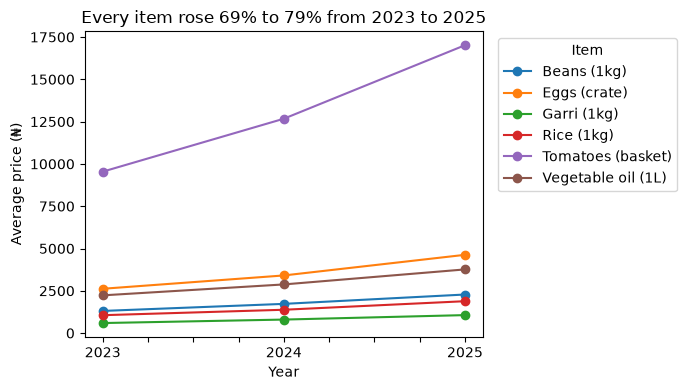

In [264]:
# 1. Keep only the year columns, then turn the table around
prices = item_price_per_year[[2023, 2024, 2025]].T

# 2. One line per item
prices.plot(marker='o', figsize=(7, 4))
plt.xlabel('Year')
plt.ylabel('Average price (₦)')
plt.title('Every item rose 69% to 79% from 2023 to 2025')
plt.legend(title='Item', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('images/price_trends.png', dpi=150, bbox_inches='tight')       # line chart
plt.show()

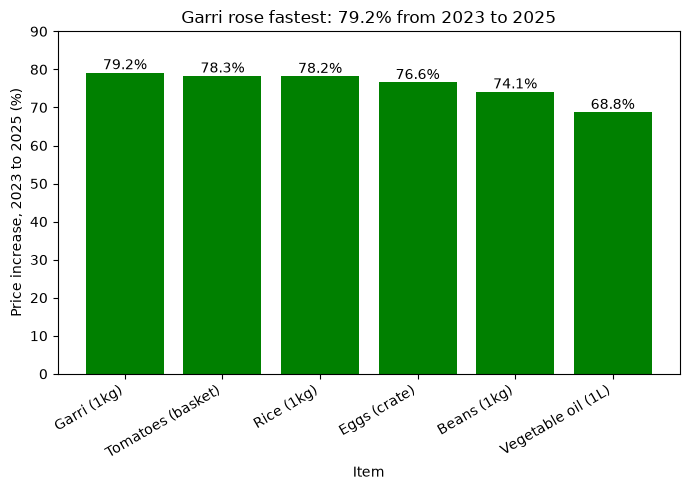

In [265]:
# 1. Sort so the biggest rise comes first
result = item_price_per_year.sort_values('pct_change', ascending=False)
result[['pct_change']]

# 2. Bar chart
plt.figure(figsize=(7, 5))
bars = plt.bar(result.index, result['pct_change'], color='green')
plt.bar_label(bars, fmt='%.1f%%')
plt.xlabel('Item')
plt.ylabel('Price increase, 2023 to 2025 (%)')
plt.title('Garri rose fastest: 79.2% from 2023 to 2025')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 90)
plt.tight_layout()
plt.savefig('images/pct_rise.png', dpi=150, bbox_inches='tight')           # % rise bar chart
plt.show()

In [238]:
item_price_per_year.index

Index(['Beans (1kg)', 'Eggs (crate)', 'Garri (1kg)', 'Rice (1kg)',
       'Tomatoes (basket)', 'Vegetable oil (1L)'],
      dtype='str', name='item')

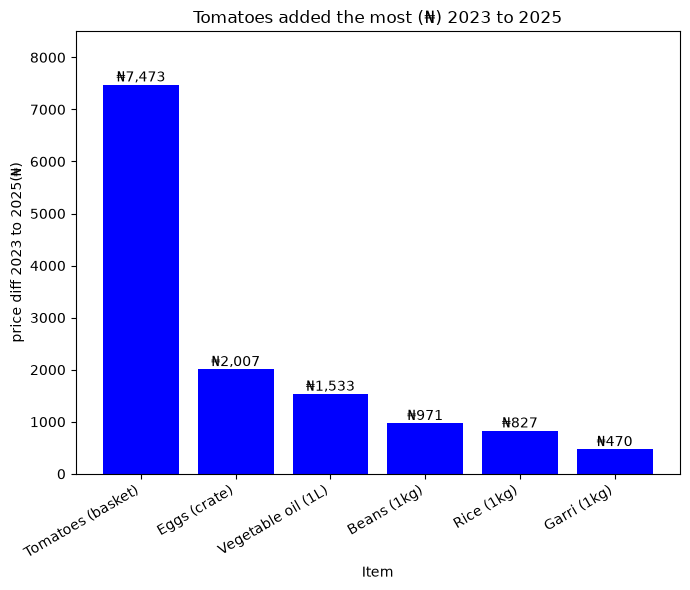

In [266]:
result = item_price_per_year.sort_values('price_diff', ascending=False)
result[['price_diff']]

plt.figure(figsize=(7, 6))
bars= plt.bar(result.index, result['price_diff'], color= 'blue')
plt.bar_label(bars, labels= [f'₦{v:,.0f}' for v in result['price_diff']])
plt.xlabel('Item')
plt.ylabel('price diff 2023 to 2025(₦)')
plt.title('Tomatoes added the most (₦) 2023 to 2025')
plt.ylim(0, 8500)
plt.xticks(rotation=30, ha= 'right')
plt.tight_layout()
plt.savefig('images/naira_rise.png', dpi=150, bbox_inches='tight')         # naira rise bar chart
plt.show()

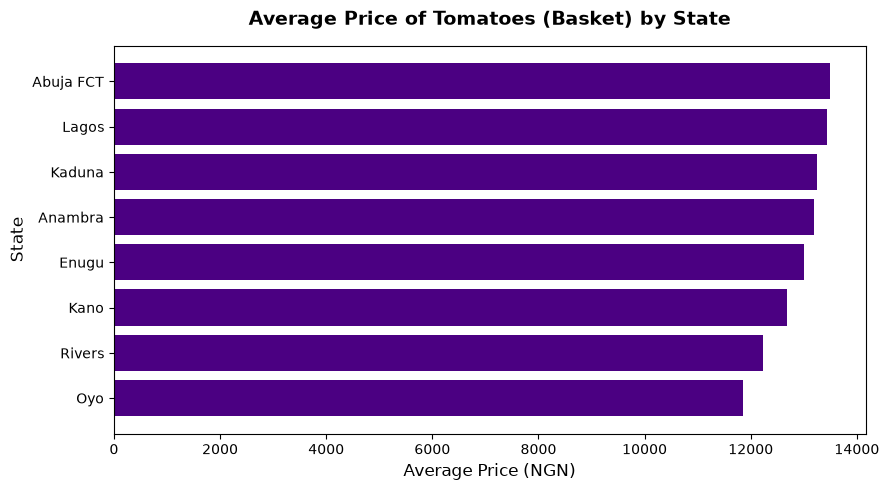

In [268]:
tomatoes = df_clean[df_clean['item'] == 'Tomatoes (basket)']

tomatoes_by_state= tomatoes.groupby('state')['price_ngn'].mean().sort_values(ascending=True).round(2)

fig, ax = plt.subplots(figsize=(9,5))
ax.barh(tomatoes_by_state.index, tomatoes_by_state.values, color='indigo')
plt.title('Average Price of Tomatoes (Basket) by State', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Price (NGN)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.tight_layout()
plt.savefig('images/tomato_by_state.png', dpi=150, bbox_inches='tight')    # state chart
plt.show()

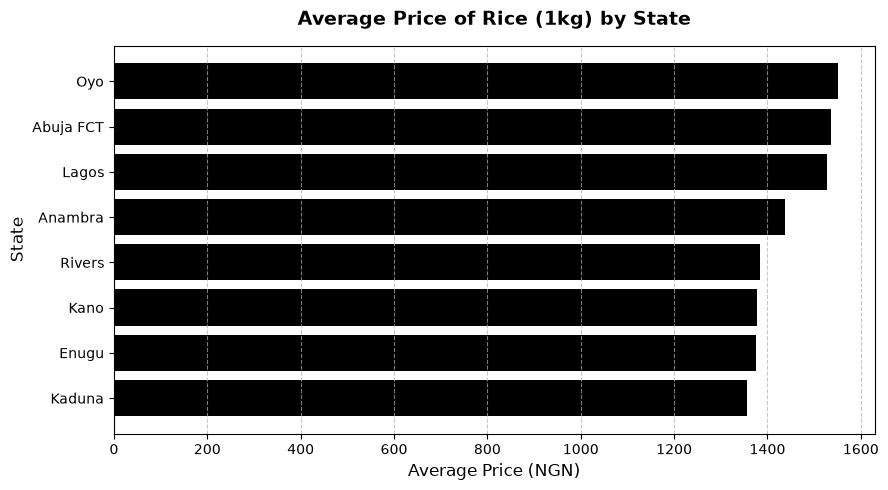

In [260]:
# 1. Filter for a single staple item (e.g., Rice) and group by state
rice_by_state = df_clean[df_clean['item'] == 'Rice (1kg)'].groupby('state')['price_ngn'].mean().sort_values(ascending=True)

# 2. Plot as a horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(rice_by_state.index, rice_by_state.values, color='black')

plt.title('Average Price of Rice (1kg) by State', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Price (NGN)', fontsize=12)
plt.ylabel('State', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

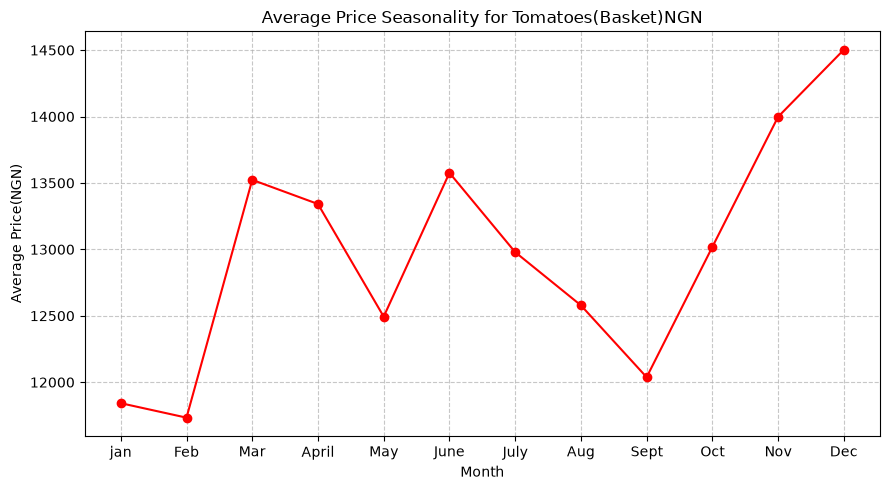

In [267]:
df_clean['month']= df_clean['date'].dt.month

tomatoes_by_month= df_clean[df_clean['item']=='Tomatoes (basket)'].groupby('month')['price_ngn'].mean()

plt.figure(figsize=(9, 5))
plt.plot(tomatoes_by_month.index, tomatoes_by_month.values, color='red', marker='o')
plt.ylabel('Average Price(NGN)')
plt.xlabel('Month')
plt.xticks(ticks=range(1, 13), labels=['jan', 'Feb', 'Mar', 'April', 'May', 'June', 'July', 'Aug', 'Sept', 'Oct', 'Nov', 'Dec'])
plt.grid(True, linestyle='--', alpha=0.7)
plt.title('Average Price Seasonality for Tomatoes(Basket)NGN')
plt.tight_layout()
plt.savefig('images/tomato_seasonality.png', dpi=150, bbox_inches='tight') # monthly line chart
plt.show()

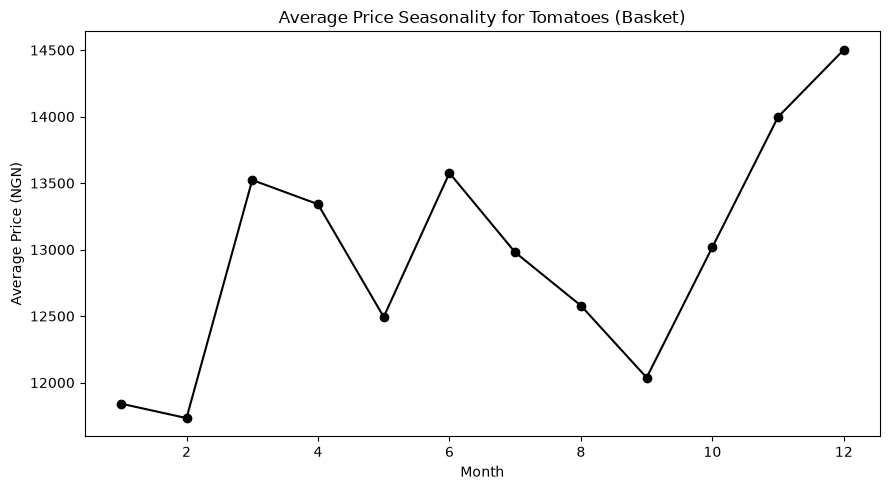

In [251]:
df_clean['month'] = df_clean['date'].dt.month

# Note: Check if your item name has a space, e.g., 'Tomatoes (basket)' vs 'Tomatoes(basket)'
tomatoes_by_month = df_clean[df_clean['item'] == 'Tomatoes (basket)'].groupby('month')['price_ngn'].mean()

plt.figure(figsize=(9, 5))
# Removed 'kind="line"' and added a comma between parameters
plt.plot(tomatoes_by_month.index, tomatoes_by_month.values, color='black', marker='o')

plt.ylabel('Average Price (NGN)')
plt.xlabel('Month')
plt.title('Average Price Seasonality for Tomatoes (Basket)')
plt.tight_layout()
plt.show()